# Do mice use the odor to find the target? The first 30 minutes of each session

`odor_search_strategy.ipynb` again, using only the trials that began in the first 30 minutes of each session (sessions last about 45). Mice are typically less engaged late in a session, so if they do use the odor it should show most clearly here. Sections 1-5 repeat the original analysis on those trials; section 6 compares the first 30 minutes with the rest of the session and with the whole-session results.

**Task.** Each trial hides one target cell in a 3 x 9 grid. On `flip_state` 0 the target is in the four rows at the low-y end of the arena and odor is delivered at that end; on `flip_state` 1 both are at the high-y end; on `flip_state` 2 there is no odor and the target can be anywhere. Odor stays on until the mouse's nose enters the target cell. The mouse then drinks at a port in the middle row, waits out a 1-3 s ITI, and the next trial starts.

**What a mouse that had learned the task would do.** Go to the odor end, and stay there until it finds the target. That gives two separable behaviors to look for:

1. **Direction** - which end does the mouse head for? (flip 0 vs flip 1)
2. **Persistence** - once at the correct end, does it stay? (odor vs no-odor)

**Why the comparisons are built the way they are.** A search ends the moment the target is found, so on a flip-0 trial every path ends at the low end no matter what the mouse was doing. Occupancy, mean position and time-at-odor-end therefore differ between flip 0 and flip 1 even for a mouse wandering at random, and are not used here. Instead:

- *Direction* uses only trials that begin in the neutral middle row and asks which end zone is entered first. A trial cannot end before the mouse has entered the target's zone, so this is not affected by where the target is.
- *Persistence and search cost* compare each odor trial against **no-odor trials with the target in the same cell and the mouse starting in the same zone**. Those trials pose an identical search problem; the only thing that differs is the odor.

Zones: `low` = y < 890 px (flip-0 target rows), `high` = y >= 1068 px (flip-1 target rows), `mid` = the row between them, which holds both water ports. Only `x` sessions (1% pinene) are analysed, and each mouse contributes ten of them: x1 to x10 (x1-x6 and x8-x11 for mouse 9007, which has no x7). The `o` and `t` sessions were shaping sessions and are left out, as is x0, which only three mice ran.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats as sps

from src import config as cfg
from src.trials import load_trials          # run `python -m src.trials` to rebuild output/trials.csv
from src.stats import stratified_diff, per_mouse, summarize, logistic_fit
from src.trajectories import load_sessions

pd.set_option('display.width', 200, 'display.precision', 3)

SESSION_TYPES = ['x']
FLIP_COLOR = {0: '#2a78d6', 1: '#eb6834', 2: '#8a8985'}
FLIP_LABEL = {0: 'flip 0 (odor low)', 1: 'flip 1 (odor high)', 2: 'flip 2 (no odor)'}
INK, MUTED, GRID = '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': MUTED,
    'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED, 'text.color': INK,
    'axes.titlesize': 10, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelsize': 9, 'xtick.labelsize': 8, 'ytick.labelsize': 8, 'legend.fontsize': 8,
    'legend.frameon': False, 'figure.dpi': 110,
})

FIRST_MIN = 30
whole = load_trials()                                  # every trial; used only for the comparison in section 6
t = whole[whole.t_start_s < FIRST_MIN * 60].copy()     # trials that began in the first 30 minutes

## 1. Data

Trials that began in the first 30 minutes of their session. One row per searched trial. A search runs from the first frame of a trial (ITI over, odor on) to the frame `target_cell` goes NaN (target consumed, odor off). Trial 0 (free reward) and trials whose target was never found are dropped. On every remaining trial the tracked nose is inside the target cell on the final frame, which confirms the grid geometry.

In [2]:
print(f"{len(t)} searched trials, {t.groupby(['mouse', 'session']).ngroups} sessions, {t.mouse.nunique()} mice")
print(f"nose inside target cell at encounter: {(t.found_err_px == 0).mean():.1%}")
overview = t.groupby('session_type').agg(
    mice=('mouse', 'nunique'), sessions=('session', lambda s: t.loc[s.index].groupby(['mouse', 'session']).ngroups),
    trials=('trial', 'size'), median_search_s=('search_s', 'median'), median_path_px=('path_px', 'median'))
overview.join(pd.crosstab(t.session_type, t.flip).add_prefix('n_flip')).loc[SESSION_TYPES]

8061 searched trials, 90 sessions, 9 mice
nose inside target cell at encounter: 100.0%


,mice,sessions,trials,median_search_s,median_path_px,n_flip0,n_flip1,n_flip2
session_type,,,,,,,,
x,9,90,8061,6.703,3586.471,2635,2703,2723


## 2. Behavioral idiosyncrasies

Three things to pin down before reading anything into flip-state differences.

**Is the mouse's position at odor onset independent of the trial type?** It has to be - the mouse has no information yet. This is the negative control for everything below.

**Side bias.** Does the mouse favor one end regardless of trial type?

**Return to the previous target.** By the time the ITI ends, has the mouse drifted back toward where it last found a target?

In [3]:
start = pd.crosstab(t.flip, t.start_zone, normalize='index')[['low', 'mid', 'high']]
chi2, p, *_ = sps.chi2_contingency(pd.crosstab(t.flip[t.odor], t.start_zone[t.odor]))
print(f"Zone at odor onset, flip 0 vs flip 1: chi2 = {chi2:.2f}, p = {p:.2f}")
start.rename(index=FLIP_LABEL)

Zone at odor onset, flip 0 vs flip 1: chi2 = 0.83, p = 0.66


start_zone,low,mid,high
flip,,,
flip 0 (odor low),0.457,0.150,0.393
flip 1 (odor high),0.468,0.144,0.388
flip 2 (no odor),0.455,0.137,0.408


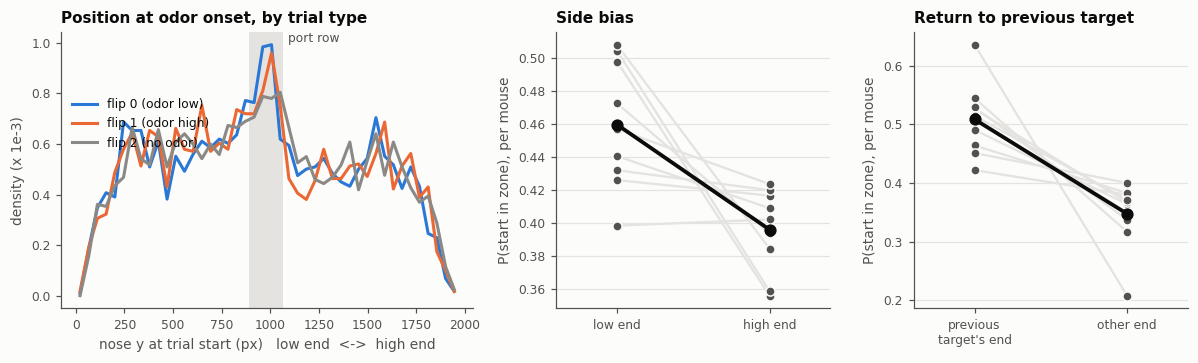

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), gridspec_kw={'width_ratios': [1.5, 1, 1]})

ax = axes[0]
bins = np.linspace(0, cfg.FRAME_H, 45)
for flip in (0, 1, 2):
    density, _ = np.histogram(t.start_y[t.flip == flip], bins=bins, density=True)
    ax.plot((bins[:-1] + bins[1:]) / 2, density * 1000, color=FLIP_COLOR[flip], lw=2, label=FLIP_LABEL[flip])
ax.axvspan(cfg.LOW_MAX_Y, cfg.HIGH_MIN_Y, color=GRID, lw=0)
ax.text(cfg.HIGH_MIN_Y + 25, ax.get_ylim()[1], 'port row', ha='left', va='top', fontsize=8, color=MUTED)
ax.set(xlabel='nose y at trial start (px)   low end  <->  high end', ylabel='density (x 1e-3)',
       title='Position at odor onset, by trial type')
ax.legend(loc='upper left', bbox_to_anchor=(0.0, 0.8))

def paired_dots(ax, a, b, labels, title, ylabel):
    for m in a.index:
        ax.plot([0, 1], [a[m], b[m]], color=GRID, lw=1.5, zorder=1)
    ax.scatter(np.zeros(len(a)), a, s=36, color=MUTED, zorder=2, edgecolor='#fcfcfb', lw=1)
    ax.scatter(np.ones(len(b)), b, s=36, color=MUTED, zorder=2, edgecolor='#fcfcfb', lw=1)
    ax.plot([0, 1], [a.mean(), b.mean()], color=INK, lw=2.5, marker='o', ms=7, zorder=3)
    ax.set(xticks=[0, 1], xticklabels=labels, xlim=(-0.4, 1.4), title=title, ylabel=ylabel)
    ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)

by_mouse = t.groupby('mouse')
paired_dots(axes[1], by_mouse.start_zone.apply(lambda z: (z == 'low').mean()),
            by_mouse.start_zone.apply(lambda z: (z == 'high').mean()),
            ['low end', 'high end'], 'Side bias', 'P(start in zone), per mouse')
prev = t[t.prev_target_zone.isin(['low', 'high'])]
prev_by_mouse = prev.groupby('mouse')[['start_zone', 'prev_target_zone']]
paired_dots(axes[2], prev_by_mouse.apply(lambda d: (d.start_zone == d.prev_target_zone).mean()),
            prev_by_mouse.apply(lambda d: ((d.start_zone != d.prev_target_zone) & (d.start_zone != 'mid')).mean()),
            ["previous\ntarget's end", 'other end'], 'Return to previous target', 'P(start in zone), per mouse')
plt.tight_layout(); plt.show()

The control holds: position at odor onset is the same for flip 0 and flip 1. Mice do have a mild preference for the low end and a mild tendency to be back at the previous target's end when the next trial starts. Both are handled below by never comparing trials across different start zones, and by stratifying the direction analysis on the previous target's end.

## 3. Direction: which end does the mouse go to first?

Trials that start in the neutral middle row only. `P(low end first)` should be near 1 on flip 0 and near 0 on flip 1 for a mouse following the odor; flip 2 shows that mouse's side bias.

**Discrimination** = P(low first | flip 0) - P(low first | flip 1), computed within mouse x previous-target-end strata so that a return-to-previous-target habit cannot produce it. 0 = odor side ignored, 1 = perfect.

In [5]:
mid = t[(t.start_zone == 'mid') & (t.first_entry != 'none')].copy()
mid['low_first'] = (mid.first_entry == 'low').astype(float)
mid['is_flip0'] = mid.flip == 0

rows = {}
for st in SESSION_TYPES:
    d = mid[mid.session_type == st]
    p_low = d.groupby('flip').low_first.mean()
    rows[st] = {'P(low first) flip 0': p_low[0], 'flip 2': p_low[2], 'flip 1': p_low[1],
                **summarize(d[d.odor], 'low_first', 'is_flip0', ['prev_target_zone'])}
direction = pd.DataFrame(rows).T.rename(columns={'effect': 'discrimination'})
direction

,P(low first) flip 0,flip 2,flip 1,discrimination,p_perm,mouse_mean,ci_lo,ci_hi,mice_same_sign,n_trials
x,0.49,0.49,0.514,-0.027,0.443,-0.04,-0.174,0.093,4/9,785


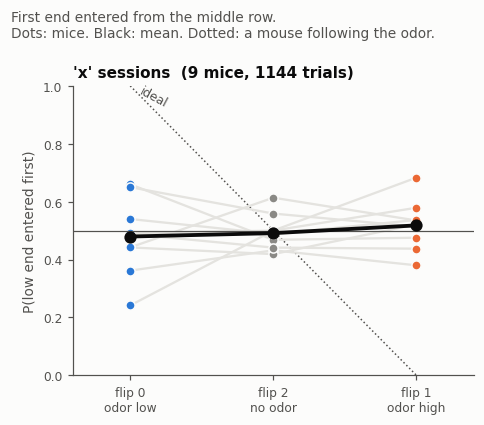

In [6]:
fig, axes = plt.subplots(1, len(SESSION_TYPES), figsize=(3.6 * len(SESSION_TYPES) + 0.8, 3.9), sharey=True, squeeze=False)
axes = axes[0]
order = [0, 2, 1]
for ax, st in zip(axes, SESSION_TYPES):
    d = mid[mid.session_type == st]
    pm = d.groupby(['mouse', 'flip']).low_first.mean().unstack()[order]
    for m in pm.index:
        ax.plot(range(3), pm.loc[m], color=GRID, lw=1.5, zorder=1)
    for i, flip in enumerate(order):
        ax.scatter(np.full(len(pm), i), pm[flip], s=36, color=FLIP_COLOR[flip], edgecolor='#fcfcfb', lw=1, zorder=2)
    ax.plot(range(3), pm.mean(), color=INK, lw=2.5, marker='o', ms=7, zorder=3)
    ax.plot(range(3), [1, 0.5, 0], color=MUTED, lw=1, ls=':', zorder=0)
    ax.axhline(0.5, color=MUTED, lw=0.8)
    ax.set(xticks=range(3), xticklabels=['flip 0\nodor low', 'flip 2\nno odor', 'flip 1\nodor high'], xlim=(-0.4, 2.4),
           ylim=(0, 1), title=f"'{st}' sessions  ({len(pm)} mice, {len(d)} trials)")
axes[0].set_ylabel('P(low end entered first)')
axes[0].text(0.05, 0.93, 'ideal', color=MUTED, fontsize=8, rotation=-28)
fig.suptitle('First end entered from the middle row.\nDots: mice. Black: mean. Dotted: a mouse following the odor.',
             x=0.01, ha='left', fontsize=9, color=MUTED)
plt.tight_layout(); plt.show()

The same question as a regression, so the odor's pull can be read next to the two idiosyncrasies on a common scale (log-odds of entering the low end first; mouse identity ignored, coefficients are descriptive):

In [7]:
def choice_model(d):
    X = np.c_[(d.flip == 0).astype(float) - (d.flip == 1), (d.prev_target_zone == 'low').astype(float) - (d.prev_target_zone == 'high')]
    intercept, coef = logistic_fit(X, d.low_first)
    return pd.Series({'odor side': coef[0], "previous target's side": coef[1], 'low-end bias': intercept})

pd.DataFrame({st: choice_model(mid[mid.session_type == st]) for st in SESSION_TYPES}).T

,odor side,previous target's side,low-end bias
x,-0.049,0.076,-0.003


## 4. Persistence and search cost: odor vs matched no-odor trials

Each search is split at the first frame the mouse is in the target's end zone:

- **approach** - everything before that (zero if the mouse started there). `wrong_end_first`: it visited the other end before the correct one.
- **local search** - everything after. `left_after_reach`: having been at the correct end, it went all the way to the other end before finding the target.

Effects are odor minus no-odor, within strata of mouse x target cell x start zone. Matching on the exact cell matters: flip 0 and flip 1 draw the center cell of their second row twice as often as any other, and those cells are easier to hit. Path effects are log2 ratios (-0.15 is about 10% shorter). Searches longer than `MAX_SEARCH_S` are dropped as disengaged.

In [8]:
MATCH = ['target_cell', 'start_zone']
METRICS = {   # name: (column, which trials)
    'whole search path (log2)':      ('log2_path_px',       ['same end', 'opposite end', 'from middle']),
    'approach path (log2)':          ('log2_reach_path_px', ['opposite end', 'from middle']),
    'P(wrong end first)':            ('wrong_end_first',    ['from middle']),
    'local search path (log2)':      ('log2_local_path_px', ['same end', 'opposite end', 'from middle']),
    'P(left correct end)':           ('left_after_reach',   ['same end', 'opposite end', 'from middle']),
}
cost = t[(t.geometry != 'target in middle') & (t.search_s <= cfg.MAX_SEARCH_S)]

rows = {}
for st in SESSION_TYPES:
    for name, (col, geoms) in METRICS.items():
        d = cost[(cost.session_type == st) & cost.geometry.isin(geoms)]
        base = d.loc[~d.odor, col].mean()
        rows[(st, name)] = {'no-odor mean': base, **summarize(d, col, 'odor', MATCH)}
matched = pd.DataFrame(rows).T
matched

no-odor mean effect p_perm mouse_mean  ci_lo  ci_hi mice_same_sign n_trials
x whole search path (log2)       11.637 -0.092  0.046     -0.094 -0.224  0.036            7/9     7654
  approach path (log2)           10.388 -0.095  0.034     -0.107  -0.26  0.046            5/9     4402
  P(wrong end first)              0.543 -0.045  0.233      -0.04 -0.158  0.077            6/9     1095
  local search path (log2)       10.917 -0.073  0.192      -0.07 -0.243  0.103            5/9     7654
  P(left correct end)             0.461 -0.024  0.051     -0.024 -0.049    0.0            7/9     7654

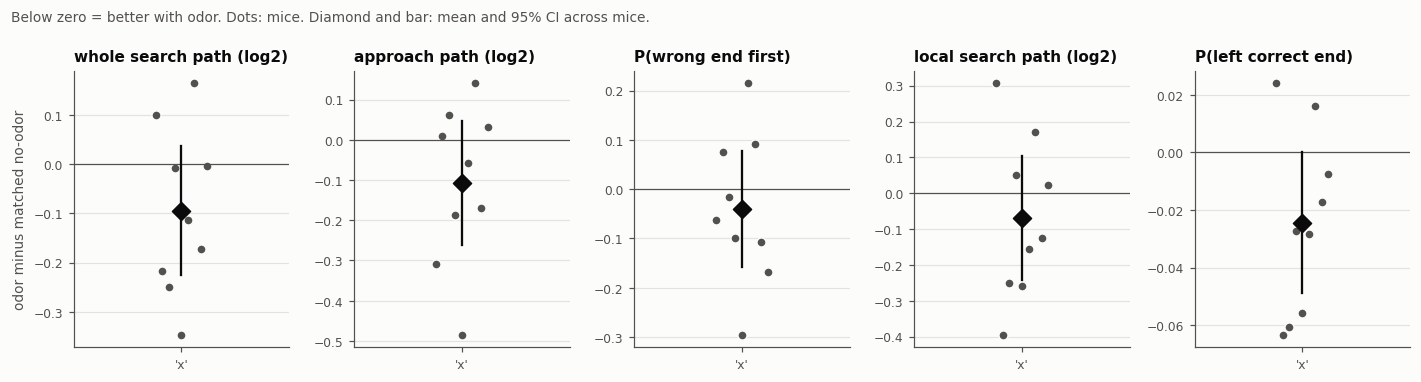

In [9]:
fig, axes = plt.subplots(1, len(METRICS), figsize=(13, 3.5))
for ax, (name, (col, geoms)) in zip(axes, METRICS.items()):
    for i, st in enumerate(SESSION_TYPES):
        d = cost[(cost.session_type == st) & cost.geometry.isin(geoms)]
        pm = per_mouse(d, col, 'odor', MATCH).dropna()
        jitter = np.linspace(-0.12, 0.12, len(pm))
        ax.scatter(i + jitter, pm, s=36, color=MUTED, edgecolor='#fcfcfb', lw=1, zorder=2)
        r = matched.loc[(st, name)]
        ax.plot([i, i], [r.ci_lo, r.ci_hi], color=INK, lw=1.5, zorder=3)
        ax.scatter([i], [r.mouse_mean], s=70, color=INK, marker='D', zorder=4)
    ax.axhline(0, color=MUTED, lw=0.8)
    ax.set(xticks=range(len(SESSION_TYPES)), xticklabels=[f"'{s}'" for s in SESSION_TYPES],
           xlim=(-0.5, len(SESSION_TYPES) - 0.5), title=name)
    ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)
axes[0].set_ylabel('odor minus matched no-odor')
fig.suptitle('Below zero = better with odor. Dots: mice. Diamond and bar: mean and 95% CI across mice.',
             x=0.01, ha='left', fontsize=9, color=MUTED)
plt.tight_layout(); plt.show()

### Do the two odor conditions differ from each other?

The same matched comparison, separately for flip 0 (against no-odor trials with a low-end target) and flip 1 (against no-odor trials with a high-end target).

In [10]:
rows = {}
for st in SESSION_TYPES:
    for flip, zone in ((0, 'low'), (1, 'high')):
        d = cost[(cost.session_type == st) & (cost.target_zone == zone)]
        rows[(st, FLIP_LABEL[flip])] = {
            'P(left correct end), odor': d.loc[d.odor, 'left_after_reach'].mean(),
            'no odor': d.loc[~d.odor, 'left_after_reach'].mean(),
            'matched diff': stratified_diff(d, 'left_after_reach', 'odor', ['mouse'] + MATCH),
            'whole path (log2), matched diff': stratified_diff(d, 'log2_path_px', 'odor', ['mouse'] + MATCH),
            'n odor': int(d.odor.sum()), 'n no odor': int((~d.odor).sum())}
pd.DataFrame(rows).T

P(left correct end), odor  no odor  matched diff  whole path (log2), matched diff  n odor  n no odor
x flip 0 (odor low)                       0.441    0.457        -0.013                           -0.079  2629.0     1171.0
  flip 1 (odor high)                      0.408    0.464        -0.035                           -0.104  2695.0     1159.0

## 5. Across sessions

Both measures by how many sessions the mouse has had (its 1st to 10th), pooling mice. If mice were learning, discrimination should climb toward 1 and the persistence effect should grow more negative.

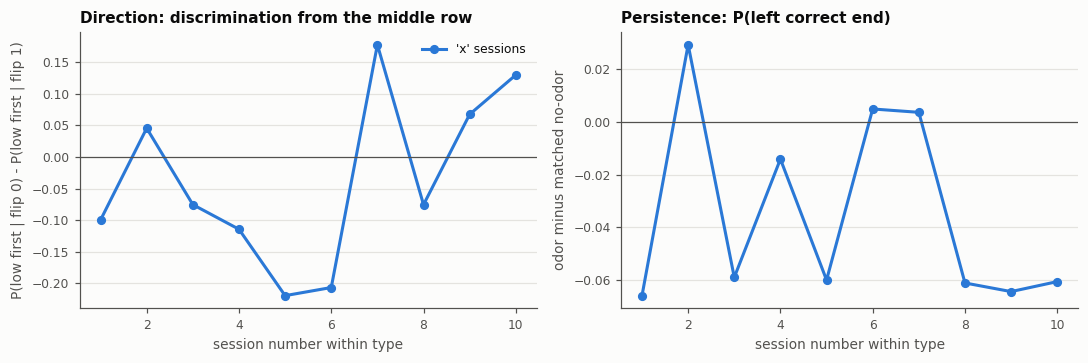

In [11]:
def by_session(d, y, label, keys, min_trials):
    out = d.groupby(['session_type', 'session_num'])[[y, label] + keys].apply(
        lambda g: pd.Series({'effect': stratified_diff(g, y, label, keys), 'n': len(g)}))
    return out[out.n >= min_trials]

disc = by_session(mid[mid.odor], 'low_first', 'is_flip0', ['mouse'], 30)
pers = by_session(cost, 'left_after_reach', 'odor', ['mouse', 'target_zone', 'start_zone'], 150)

TYPE_COLOR = {'x': '#2a78d6'}
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, data, title, ylabel in ((axes[0], disc, 'Direction: discrimination from the middle row', 'P(low first | flip 0) - P(low first | flip 1)'),
                                (axes[1], pers, 'Persistence: P(left correct end)', 'odor minus matched no-odor')):
    for st in SESSION_TYPES:
        s = data.loc[st].effect
        ax.plot(s.index, s.values, color=TYPE_COLOR[st], lw=2, marker='o', ms=5, label=f"'{st}' sessions")
    ax.axhline(0, color=MUTED, lw=0.8)
    ax.set(title=title, ylabel=ylabel, xlabel='session number within type')
    ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)
axes[0].legend()
plt.tight_layout(); plt.show()

## 6. The first 30 minutes against the rest of the session

Three sets of trials: the whole session, the first 30 minutes (sections 1-5), and everything after 30 minutes. The first 30 minutes are part of the whole session, so those two cannot be tested against each other; the comparison that can be tested is **first 30 minutes against after 30 minutes**, which share no trials. It is made within mouse.

### Are mice less engaged after 30 minutes?

In [12]:
late = whole[whole.t_start_s >= FIRST_MIN * 60]
PARTS = {'whole session': whole, f'first {FIRST_MIN} min': t, f'after {FIRST_MIN} min': late}
FIRST, AFTER = list(PARTS)[1:]

def paired(m, a=FIRST, b=AFTER):
    """Across-mouse summary of b - a for a mouse x part table."""
    d = m[[a, b]].dropna()
    diff = d[b] - d[a]
    lo, hi = sps.t.interval(0.95, len(d) - 1, diff.mean(), sps.sem(diff))
    return pd.Series({a: d[a].mean(), b: d[b].mean(), 'after - first': diff.mean(), 'ci_lo': lo, 'ci_hi': hi,
                      'p (paired t)': sps.ttest_rel(d[b], d[a]).pvalue, 'mice lower after': f'{int((diff < 0).sum())}/{len(d)}'})

# minutes available in each part of each session, for the trial rate
minutes = load_sessions().set_index(['mouse', 'session']).duration_s / 60
available = {FIRST: minutes.clip(upper=FIRST_MIN), AFTER: (minutes - FIRST_MIN).clip(lower=0)}

def per_mouse_table(f):
    return pd.DataFrame({part: f(PARTS[part], part) for part in (FIRST, AFTER)})

no_odor = lambda d: d[~d.odor & (d.geometry != 'target in middle')]
engagement = {
    'trials per minute': per_mouse_table(lambda d, part: (d.groupby(['mouse', 'session']).size() / available[part]).groupby('mouse').mean()),
    'median search (s)': per_mouse_table(lambda d, part: d.groupby('mouse').search_s.median()),
    'median search path (px)': per_mouse_table(lambda d, part: d.groupby('mouse').path_px.median()),
    'searches over 120 s (share)': per_mouse_table(lambda d, part: (d.search_s > cfg.MAX_SEARCH_S).groupby(d.mouse).mean()),
    'no-odor P(left correct end)': per_mouse_table(lambda d, part: no_odor(d).groupby('mouse').left_after_reach.mean()),
}
print({part: len(d) for part, d in PARTS.items()})
pd.DataFrame({name: paired(m) for name, m in engagement.items()}).T

{'whole session': 10621, 'first 30 min': 8061, 'after 30 min': 2560}


,first 30 min,after 30 min,after - first,ci_lo,ci_hi,p (paired t),mice lower after
trials per minute,2.986,1.922,-1.063,-1.333,-0.793,0.0,9/9
median search (s),6.77,10.86,4.091,2.721,5.46,0.0,0/9
median search path (px),3618.206,4668.141,1049.935,456.53,1643.339,0.004,0/9
searches over 120 s (share),0.003,0.021,0.018,0.009,0.027,0.002,0/9
no-odor P(left correct end),0.463,0.486,0.023,-0.036,0.082,0.39,4/9


### Does the odor's effect differ?

The direction measure and the five matched odor-vs-no-odor measures, computed exactly as above for each set of trials. Then, per mouse, the effect after 30 minutes minus the effect in the first 30.

In [13]:
def measure_args(d):
    """{name: (trials, outcome, label, strata)} for one set of trials - the arguments summarize / per_mouse take."""
    m = d[(d.start_zone == 'mid') & (d.first_entry != 'none') & d.odor].copy()
    m['low_first'] = (m.first_entry == 'low').astype(float)
    m['is_flip0'] = m.flip == 0
    c = d[(d.geometry != 'target in middle') & (d.search_s <= cfg.MAX_SEARCH_S)]
    out = {'direction: discrimination': (m, 'low_first', 'is_flip0', ['prev_target_zone'])}
    for name, (col, geoms) in METRICS.items():
        out[name] = (c[c.geometry.isin(geoms)], col, 'odor', MATCH)
    return out

args = {part: measure_args(d) for part, d in PARTS.items()}
MEASURES = list(args[FIRST])
by_part = pd.DataFrame({(name, part): summarize(*args[part][name]) for name in MEASURES for part in PARTS}).T
by_part

effect p_perm mouse_mean  ci_lo  ci_hi mice_same_sign n_trials
direction: discrimination whole session -0.003  0.925     -0.022 -0.153  0.108            3/9     1069
                          first 30 min  -0.027  0.443      -0.04 -0.174  0.093            4/9      785
                          after 30 min   0.051  0.418     -0.032 -0.293  0.229            4/9      284
whole search path (log2)  whole session -0.117  0.007     -0.115  -0.24  0.009            7/9    10043
                          first 30 min  -0.092  0.046     -0.094 -0.224  0.036            7/9     7654
                          after 30 min  -0.243  0.013     -0.206 -0.455  0.043            6/9     2389
approach path (log2)      whole session  -0.11  0.006     -0.109 -0.224  0.006            7/9     5817
                          first 30 min  -0.095  0.034     -0.107  -0.26  0.046            5/9     4402
                          after 30 min  -0.148  0.138     -0.067 -0.391  0.257            4/9     1415
P(wrong end first)        whole session -0.044  0.149     -0.037 -0.119  0.044            6/9     1491
                          first 30 min  -0.045  0.233      -0.04 -0.158  0.077            6/9     1095
                          after 30 min  -0.033  0.657      0.075 -0.188  0.339            3/9      396
local search path (log2)  whole session -0.085  0.093     -0.079 -0.223  0.064            7/9    10043
                          first 30 min  -0.073  0.192      -0.07 -0.243  0.103            5/9     7654
                          after 30 min  -0.182  0.136     -0.155 -0.385  0.076            7/9     2389
P(left correct end)       whole session -0.034  0.003     -0.033 -0.057 -0.009            7/9    10043
                          first 30 min  -0.024  0.051     -0.024 -0.049    0.0            7/9     7654
                          after 30 min  -0.082  0.001     -0.071 -0.128 -0.014            7/9     2389

In [14]:
mouse_fx = {name: pd.DataFrame({part: per_mouse(*args[part][name]) for part in PARTS}) for name in MEASURES}
first_vs_after = pd.DataFrame({name: paired(mouse_fx[name]) for name in MEASURES}).T
first_vs_after

,first 30 min,after 30 min,after - first,ci_lo,ci_hi,p (paired t),mice lower after
direction: discrimination,-0.04,-0.032,0.008,-0.203,0.22,0.929,5/9
whole search path (log2),-0.094,-0.206,-0.112,-0.398,0.174,0.393,4/9
approach path (log2),-0.107,-0.067,0.04,-0.34,0.42,0.813,4/9
P(wrong end first),-0.04,0.075,0.116,-0.192,0.424,0.411,4/9
local search path (log2),-0.07,-0.155,-0.085,-0.39,0.22,0.54,5/9
P(left correct end),-0.024,-0.071,-0.047,-0.112,0.018,0.137,6/9


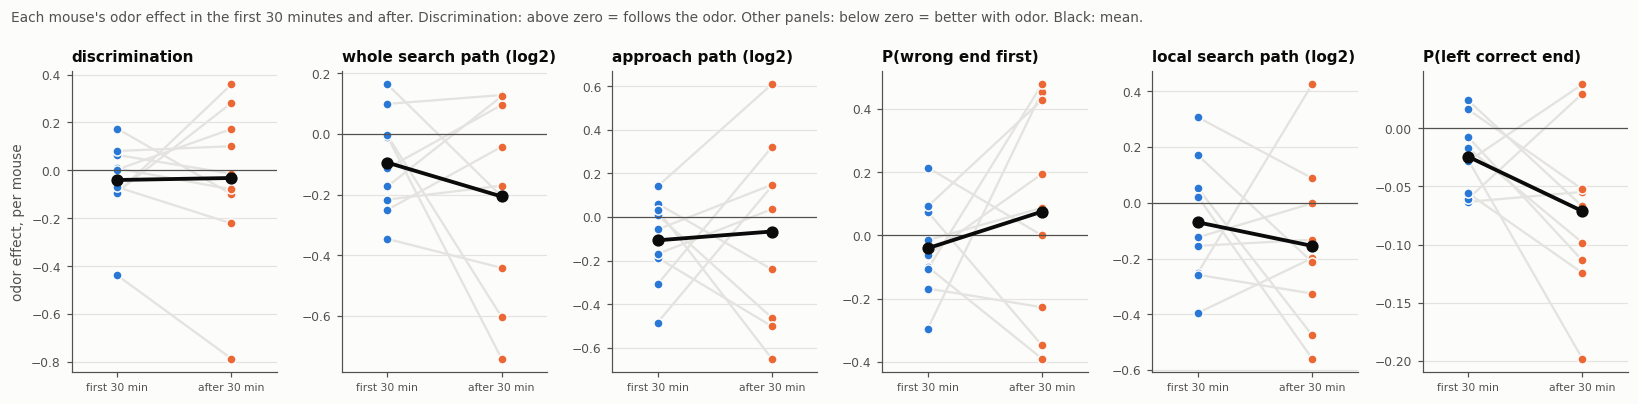

In [15]:
PART_COLOR = {FIRST: '#2a78d6', AFTER: '#eb6834'}
fig, axes = plt.subplots(1, len(MEASURES), figsize=(15, 3.7))
for ax, name in zip(axes, MEASURES):
    d = mouse_fx[name][[FIRST, AFTER]].dropna()
    for m in d.index:
        ax.plot([0, 1], d.loc[m], color=GRID, lw=1.5, zorder=1)
    for i, part in enumerate((FIRST, AFTER)):
        ax.scatter(np.full(len(d), i), d[part], s=36, color=PART_COLOR[part], edgecolor='#fcfcfb', lw=1, zorder=2)
    ax.plot([0, 1], d.mean(), color=INK, lw=2.5, marker='o', ms=7, zorder=3)
    ax.axhline(0, color=MUTED, lw=0.8)
    ax.set(xticks=[0, 1], xticklabels=[FIRST, AFTER], xlim=(-0.4, 1.4), title=name.replace('direction: ', ''))
    ax.tick_params(axis='x', labelsize=7)
    ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)
axes[0].set_ylabel('odor effect, per mouse')
fig.suptitle("Each mouse's odor effect in the first 30 minutes and after. Discrimination: above zero = follows the odor. "
             "Other panels: below zero = better with odor. Black: mean.", x=0.01, ha='left', fontsize=9, color=MUTED)
plt.tight_layout(); plt.show()

**Mice are clearly less engaged after 30 minutes.** In all nine mice the trial rate drops (3.0 to 1.9 per minute), the median search lengthens (6.8 to 10.9 s) and long, disengaged searches become more common (0.3% to 2.1% over 120 s). The first 30 minutes hold 76% of a session's trials.

**But the odor's effect is not larger while they are engaged. If anything it is larger afterwards.**
- *Direction:* discrimination is zero in every set of trials (-0.03 in the first 30 minutes, 0.05 after, 0.00 for the whole session).
- *Persistence and cost:* in the first 30 minutes the path is about 6% shorter with odor (log2 -0.09) and mice leave the correct end on 2.4 points fewer trials. After 30 minutes those are 16% (log2 -0.24) and 8.2 points.
- *Is that difference real?* Not demonstrably. Within mouse, the after-minus-first difference is in that direction for both (-0.11 log2, -4.7 points) but neither is reliable (p = 0.39 and 0.14; 4/9 and 6/9 mice). The after-30 set is a quarter of the trials, and per-mouse effects there are noisy, as the figure shows.

So restricting to the first 30 minutes does not sharpen the picture; it removes the part of the session where the odor effect is nominally strongest, and the estimates move toward zero. The whole-session effects are not an average dragged down by disengaged trials.

## Summary

**The first 30 minutes look like the whole session, with a slightly weaker odor effect.**

**Direction (flip 0 vs flip 1).** From the middle row (9 mice, 785 odor trials), discrimination is -0.03 (95% CI across mice -0.17 to 0.09). The odor side has no detectable influence on which end the mouse goes to. In the regression its weight (-0.05) is no larger than the previous-target habit (0.08).

**Odor vs matched no-odor (persistence and cost).** The effects point the same way as in the whole session but are smaller and no longer clear of chance: the search path is about 6% shorter (log2 ratio -0.09, p = 0.046, 7/9 mice; whole session 8%, p = 0.007) and mice leave the correct end on 2.4 percentage points fewer trials than the 46% no-odor baseline (p = 0.051, 7/9 mice; whole session 3.4 points, p = 0.003). None of the five tests survives a Bonferroni correction here.

**Idiosyncrasies.** Position at odor onset is independent of trial type (p = 0.66). Mice start in the low end more often than the high end (46% vs 40%) and are more likely to be at the previous target's end than the other one (51% vs 35%).

**No learning across sessions.** Neither measure trends over the ten sessions.

**First 30 minutes against the rest (section 6).**
- Mice are less engaged after 30 minutes: fewer trials per minute and longer searches, in all nine mice.
- The odor effect is not concentrated in the engaged part of the session. It is nominally larger after 30 minutes (path 16% shorter, 8.2 points less leaving, against 6% and 2.4 points before), though the within-mouse difference is not reliable (p = 0.39 and 0.14).
- Direction is at chance throughout.

**Reading the results.**
- Disengagement is not what keeps the odor effect small. Dropping the late trials weakens the result, partly through losing a quarter of the data and partly because those trials carry a nominally larger effect.
- One reading of the larger late effect: searches are longer when mice are less engaged, so there is more for a cue to save. That is a guess; the data here do not test it.
- A trial belongs to the first 30 minutes if it began in them, so the last such trial of a session can run past the 30-minute mark.
- p-values are unadjusted.
- Excluded: the `o` and `t` shaping sessions, sessions beyond each mouse's ten, trial 0 of each session, trials with no target found, and (sections 4 and 6) searches over 120 s and no-odor trials with the target in the middle row.